In [1]:

# Tahap 1: Persiapan lingkungan analisis

!pip -q install earthengine-api geemap pandas matplotlib

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt

print("Instalasi dan impor pustaka selesai.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 34.3 MB/s eta 0:00:00
Instalasi dan impor pustaka selesai.


In [3]:

import ee

PROJECT_ID = "true-campus-479905-q0"

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print("Koneksi Earth Engine berhasil!")

hasil = ee.Number(2).add(3).getInfo()
print("Hasil tes:", hasil)


Koneksi Earth Engine berhasil!
Hasil tes: 5


In [4]:

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt

print("Pustaka analisis siap digunakan.")


Pustaka analisis siap digunakan.


In [5]:

# Dataset Global Forest Change 2000–2025
gfc = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")

# Ambil dua band utama
tree_cover = gfc.select("treecover2000")
loss_year = gfc.select("lossyear")

# Informasi dasar dataset
print("Band dataset:", gfc.bandNames().getInfo())
print("Resolusi nominal (meter):",
      gfc.select("treecover2000").projection().nominalScale().getInfo())


Band dataset: ['treecover2000', 'loss', 'gain', 'lossyear', 'first_b30', 'first_b40', 'first_b50', 'first_b70', 'last_b30', 'last_b40', 'last_b50', 'last_b70', 'datamask']
Resolusi nominal (meter): 27.829872698318393


In [6]:

# Batas administrasi level provinsi
gaul = ee.FeatureCollection("FAO/GAUL/2015/level1")

# Provinsi di Pulau Sumatra dan pulau-pulau sekitarnya
provinsi_sumatra = [
    "Aceh",
    "Sumatera Utara",
    "Sumatera Barat",
    "Riau",
    "Jambi",
    "Sumatera Selatan",
    "Bengkulu",
    "Lampung",
    "Kepulauan Bangka Belitung",
    "Kepulauan Riau"
]

sumatra = gaul.filter(
    ee.Filter.eq("ADM0_NAME", "Indonesia")
).filter(
    ee.Filter.inList("ADM1_NAME", provinsi_sumatra)
)

print("Provinsi yang ditemukan:")
print(sumatra.aggregate_array("ADM1_NAME").getInfo())
print("Jumlah fitur wilayah:", sumatra.size().getInfo())


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


Provinsi yang ditemukan:
['Sumatera Selatan', 'Riau', 'Bengkulu', 'Jambi', 'Lampung', 'Sumatera Barat', 'Sumatera Utara']
Jumlah fitur wilayah: 7


In [7]:

# Fokuskan peta pada wilayah penelitian
peta = geemap.Map()
peta.centerObject(sumatra, 5)

# Lapisan tutupan kanopi pohon tahun 2000
peta.addLayer(
    tree_cover.clipToCollection(sumatra),
    {
        "min": 0,
        "max": 100,
        "palette": ["white", "yellow", "green", "darkgreen"]
    },
    "Tutupan kanopi pohon tahun 2000 (%)"
)

# Lapisan tahun kehilangan tutupan pohon
peta.addLayer(
    loss_year.updateMask(loss_year.gt(0)).clipToCollection(sumatra),
    {
        "min": 1,
        "max": 25,
        "palette": ["yellow", "orange", "red", "darkred"]
    },
    "Tahun kehilangan tutupan pohon (2001–2025)"
)

# Batas wilayah penelitian
peta.addLayer(
    sumatra.style(
        color="blue",
        fillColor="00000000",
        width=2
    ),
    {},
    "Batas wilayah penelitian"
)

peta


Map(center=[-1.0962175978096946, 102.08830986605419], controls=(WidgetControl(options=['position', 'transparen…

In [13]:

# Uji analisis untuk tahun 2025
tahun_uji = 2025
kode_tahun = tahun_uji - 2000

print("Memulai pengujian luas kehilangan tahun 2025...")

mask = loss_year.eq(kode_tahun)

luas = (
    ee.Image.pixelArea()
    .divide(10000)
    .updateMask(mask)
)

hasil_uji = luas.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=sumatra.geometry(),
    scale=1000,
    maxPixels=1e13,
    tileScale=4
).get("area").getInfo()

print("Pengujian selesai.")
print("Luas kehilangan tutupan pohon tahun 2025:",
      0 if hasil_uji is None else round(hasil_uji, 2),
      "hektare")


Memulai pengujian luas kehilangan tahun 2025...
Pengujian selesai.
Luas kehilangan tutupan pohon tahun 2025: 2008249.87 hektare


In [14]:

# Tahap 4: Rekap kehilangan tutupan pohon tahunan

import ee
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Memulai rekap tahunan 2001–2025...")

# Gabungkan luas piksel (ha) dan kode tahun kehilangan
luas_ha = ee.Image.pixelArea().divide(10000).rename("luas_ha")
kode_tahun = loss_year.rename("kode_tahun")

gabungan = luas_ha.addBands(kode_tahun).updateMask(
    kode_tahun.gt(0)
)

# Satu operasi agregasi untuk seluruh tahun
hasil = gabungan.reduceRegion(
    reducer=ee.Reducer.sum().group(
        groupField=1,
        groupName="kode_tahun"
    ),
    geometry=sumatra.geometry(),
    scale=1000,
    maxPixels=1e13,
    tileScale=4
)

print("Permintaan dikirim. Menunggu hasil Earth Engine...")

kelompok = hasil.get("groups").getInfo()

# Ubah hasil ke tabel
rekap = {
    int(item["kode_tahun"]) + 2000: item["sum"]
    for item in kelompok
}

data = pd.DataFrame({"tahun": range(2001, 2026)})
data["kehilangan_ha"] = data["tahun"].map(rekap).fillna(0)

print("Rekap selesai.")
display(data.round(2))


Memulai rekap tahunan 2001–2025...
Permintaan dikirim. Menunggu hasil Earth Engine...
Rekap selesai.


,tahun,kehilangan_ha
0,2001,956743.32
1,2002,827475.20
2,2003,412168.63
3,2004,1360049.40
4,2005,1369704.79
5,2006,1436976.13
6,2007,1286289.31
7,2008,1390716.13
8,2009,1719083.86
9,2010,1303024.61


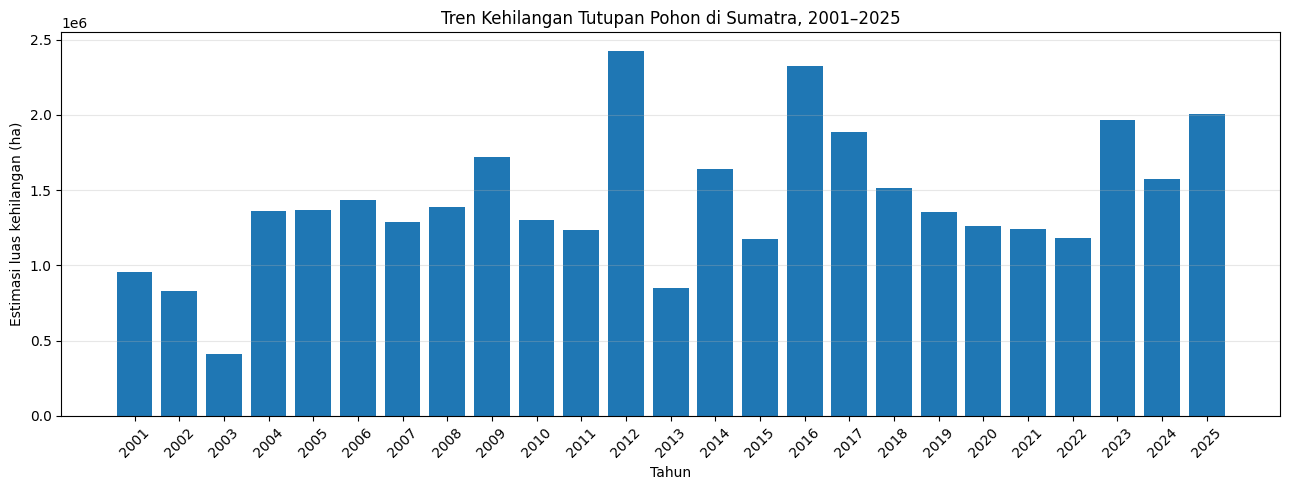

Tahun dengan estimasi kehilangan tertinggi: 2012
Estimasi luas: 2,426,720.49 ha


In [15]:

plt.figure(figsize=(13, 5))
plt.bar(data["tahun"], data["kehilangan_ha"])

plt.title("Tren Kehilangan Tutupan Pohon di Sumatra, 2001–2025")
plt.xlabel("Tahun")
plt.ylabel("Estimasi luas kehilangan (ha)")
plt.xticks(data["tahun"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

tertinggi = data.loc[data["kehilangan_ha"].idxmax()]
print("Tahun dengan estimasi kehilangan tertinggi:",
      int(tertinggi["tahun"]))
print("Estimasi luas:",
      f"{tertinggi['kehilangan_ha']:,.2f} ha")


In [16]:

nama_file = "rekap_kehilangan_tutupan_pohon_sumatra_2001_2025.csv"

data.to_csv(nama_file, index=False)

from google.colab import files
files.download(nama_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STATISTIK KEHILANGAN TUTUPAN POHON SUMATRA
Rata-rata per tahun : 1,428,069.05 ha
Total periode       : 35,701,726.23 ha
Tahun tertinggi     : 2012
Tahun terendah      : 2003


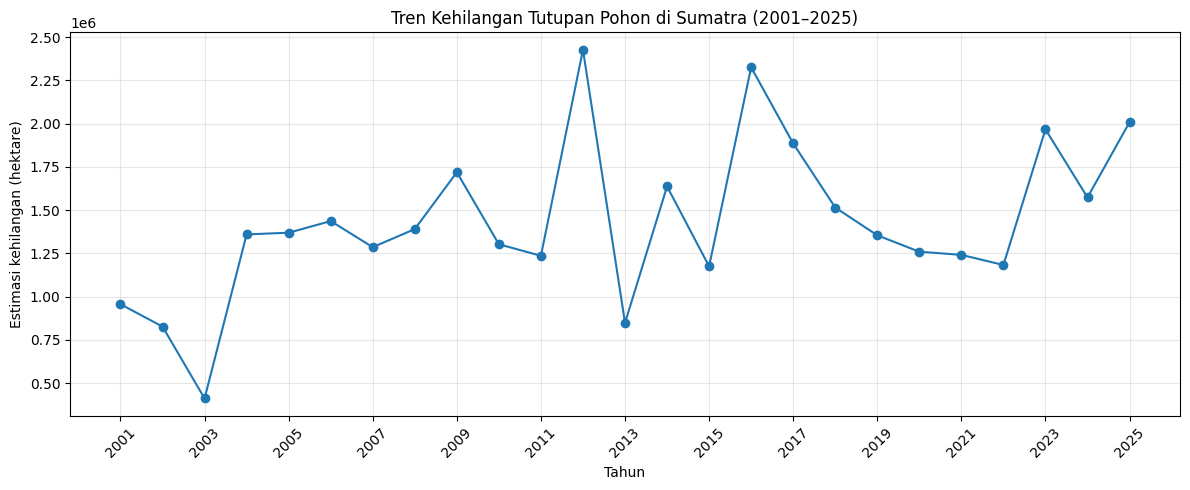

In [17]:

# Tahap 7: Analisis statistik kehilangan tutupan pohon

# Statistik deskriptif
print("STATISTIK KEHILANGAN TUTUPAN POHON SUMATRA")
print("=" * 50)
print(f"Rata-rata per tahun : {data['kehilangan_ha'].mean():,.2f} ha")
print(f"Total periode       : {data['kehilangan_ha'].sum():,.2f} ha")
print(f"Tahun tertinggi     : {int(data.loc[data['kehilangan_ha'].idxmax(), 'tahun'])}")
print(f"Tahun terendah      : {int(data.loc[data['kehilangan_ha'].idxmin(), 'tahun'])}")

# Grafik tren tahunan
plt.figure(figsize=(12, 5))
plt.plot(data["tahun"], data["kehilangan_ha"], marker="o")
plt.title("Tren Kehilangan Tutupan Pohon di Sumatra (2001–2025)")
plt.xlabel("Tahun")
plt.ylabel("Estimasi kehilangan (hektare)")
plt.xticks(range(2001, 2026, 2), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Tahap 8: Analisis kehilangan tutupan pohon per provinsi

import ee
import pandas as pd
import matplotlib.pyplot as plt

print("Memulai analisis per provinsi...")

# Luas piksel dalam hektare
luas_ha = ee.Image.pixelArea().divide(10000).rename("luas_ha")

# Masker kehilangan pada periode 2001–2025
mask = loss_year.gt(0)

# Gabungkan citra luas dan kehilangan
citra = luas_ha.updateMask(mask)

def hitung_provinsi(fitur):
    hasil = citra.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=fitur.geometry(),
        scale=1000,
        maxPixels=1e13,
        tileScale=4
    )

    return fitur.set(
        "kehilangan_ha",
        hasil.get("luas_ha", 0)
    )

# Proses satu provinsi per fitur
hasil_provinsi = sumatra.map(hitung_provinsi)

fitur_list = hasil_provinsi.getInfo()["features"]

provinsi_data = pd.DataFrame([
    {
        "provinsi": f["properties"].get("ADM1_NAME", "Tidak diketahui"),
        "kehilangan_ha": f["properties"].get("kehilangan_ha") or 0
    }
    for f in fitur_list
])

provinsi_data = provinsi_data.sort_values(
    "kehilangan_ha", ascending=False
).reset_index(drop=True)

display(provinsi_data.round(2))


Memulai analisis per provinsi...


,provinsi,kehilangan_ha
0,Riau,8401056.96
1,Sumatera Selatan,8238841.97
2,Sumatera Utara,6423239.85
3,Jambi,4469271.85
4,Sumatera Barat,3456673.38
5,Lampung,3127861.70
6,Bengkulu,1624748.50


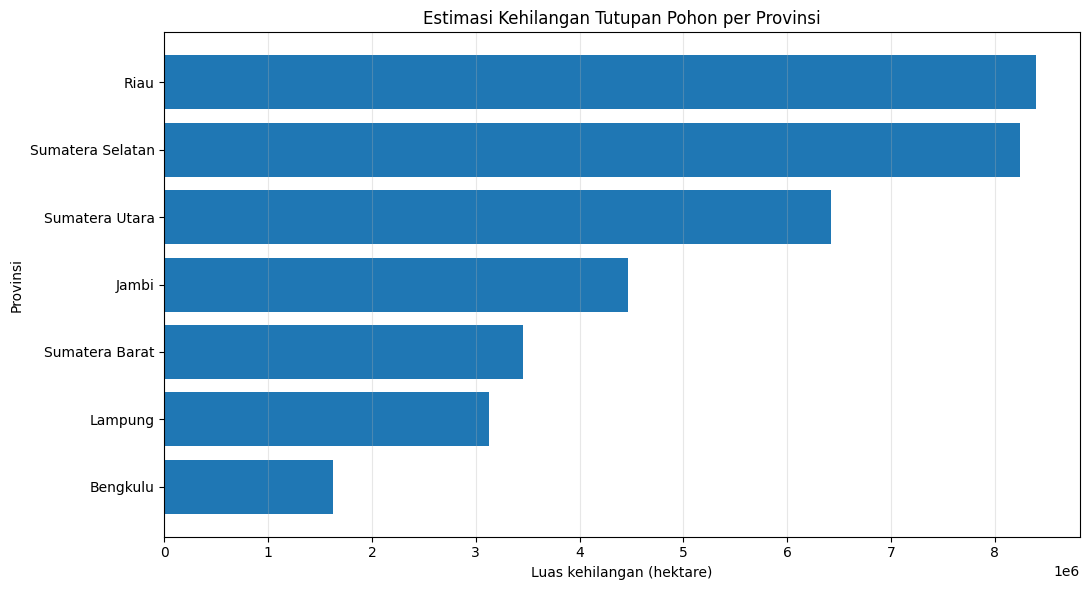

Provinsi dengan estimasi kehilangan terbesar: Riau
Estimasi luas: 8,401,056.96 hektare


In [19]:

plt.figure(figsize=(11, 6))

plt.barh(
    provinsi_data["provinsi"],
    provinsi_data["kehilangan_ha"]
)

plt.gca().invert_yaxis()
plt.title("Estimasi Kehilangan Tutupan Pohon per Provinsi")
plt.xlabel("Luas kehilangan (hektare)")
plt.ylabel("Provinsi")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

terbesar = provinsi_data.iloc[0]

print("Provinsi dengan estimasi kehilangan terbesar:",
      terbesar["provinsi"])
print("Estimasi luas:",
      f"{terbesar['kehilangan_ha']:,.2f} hektare")


In [20]:
# Menyimpan hasil analisis tahunan ke file CSV
data.to_csv("hasil_kehilangan_tutupan_pohon_sumatra.csv", index=False)

# Menampilkan tabel hasil
display(data.round(2))

print("Data tahunan berhasil disimpan.")

,tahun,kehilangan_ha
0,2001,956743.32
1,2002,827475.20
2,2003,412168.63
3,2004,1360049.40
4,2005,1369704.79
5,2006,1436976.13
6,2007,1286289.31
7,2008,1390716.13
8,2009,1719083.86
9,2010,1303024.61


Data tahunan berhasil disimpan.


In [21]:
# Menyimpan hasil analisis per provinsi
provinsi_data.to_csv("hasil_kehilangan_tutupan_pohon_per_provinsi.csv", index=False)

# Menampilkan hasil
display(provinsi_data.round(2))

print("Data per provinsi berhasil disimpan.")

,provinsi,kehilangan_ha
0,Riau,8401056.96
1,Sumatera Selatan,8238841.97
2,Sumatera Utara,6423239.85
3,Jambi,4469271.85
4,Sumatera Barat,3456673.38
5,Lampung,3127861.70
6,Bengkulu,1624748.50


Data per provinsi berhasil disimpan.


In [22]:
from google.colab import files

files.download("hasil_kehilangan_tutupan_pohon_sumatra.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download("hasil_kehilangan_tutupan_pohon_per_provinsi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# Statistik ringkas dari hasil analisis tahunan
tahun_tertinggi = data.loc[data["kehilangan_ha"].idxmax()]
tahun_terendah = data.loc[data["kehilangan_ha"].idxmin()]

total_kehilangan = data["kehilangan_ha"].sum()
rata_rata = data["kehilangan_ha"].mean()

print("=== RINGKASAN ANALISIS SUMATRA ===")
print(f"Periode analisis: {data['tahun'].min()}–{data['tahun'].max()}")
print(f"Total estimasi kehilangan: {total_kehilangan:,.2f} hektare")
print(f"Rata-rata per tahun: {rata_rata:,.2f} hektare")
print(
    f"Tahun dengan nilai tertinggi: {int(tahun_tertinggi['tahun'])} "
    f"({tahun_tertinggi['kehilangan_ha']:,.2f} hektare)"
)
print(
    f"Tahun dengan nilai terendah: {int(tahun_terendah['tahun'])} "
    f"({tahun_terendah['kehilangan_ha']:,.2f} hektare)"
)

=== RINGKASAN ANALISIS SUMATRA ===
Periode analisis: 2001–2025
Total estimasi kehilangan: 35,701,726.23 hektare
Rata-rata per tahun: 1,428,069.05 hektare
Tahun dengan nilai tertinggi: 2012 (2,426,720.49 hektare)
Tahun dengan nilai terendah: 2003 (412,168.63 hektare)


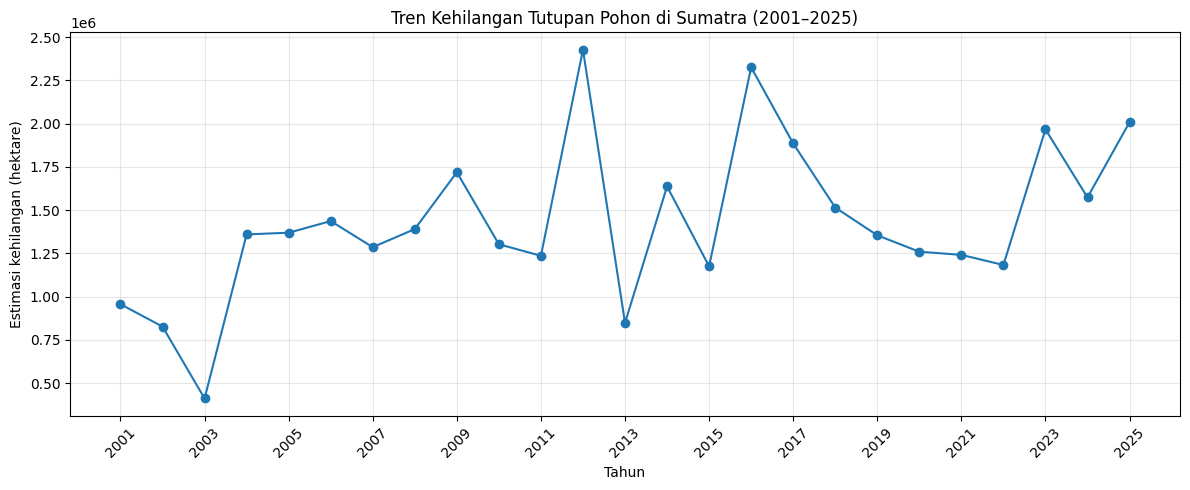

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    data["tahun"],
    data["kehilangan_ha"],
    marker="o"
)

plt.title("Tren Kehilangan Tutupan Pohon di Sumatra (2001–2025)")
plt.xlabel("Tahun")
plt.ylabel("Estimasi kehilangan (hektare)")
plt.xticks(data["tahun"][::2], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
tahun_tertinggi = data.loc[data["kehilangan_ha"].idxmax()]
tahun_terendah = data.loc[data["kehilangan_ha"].idxmin()]

print("=== HASIL ANALISIS TAHUNAN ===")
print(
    f"Tahun tertinggi: {int(tahun_tertinggi['tahun'])}"
)
print(
    f"Estimasi kehilangan: "
    f"{tahun_tertinggi['kehilangan_ha']:,.2f} hektare"
)

print()

print(
    f"Tahun terendah: {int(tahun_terendah['tahun'])}"
)
print(
    f"Estimasi kehilangan: "
    f"{tahun_terendah['kehilangan_ha']:,.2f} hektare"
)

=== HASIL ANALISIS TAHUNAN ===
Tahun tertinggi: 2012
Estimasi kehilangan: 2,426,720.49 hektare

Tahun terendah: 2003
Estimasi kehilangan: 412,168.63 hektare


In [27]:
# Memeriksa nama dan jumlah provinsi yang terambil
print("Jumlah fitur provinsi:", sumatra.size().getInfo())

nama_provinsi = sumatra.aggregate_array("ADM1_NAME").getInfo()

print("\nDaftar nama provinsi yang ditemukan:")
for nama in sorted(nama_provinsi):
    print("-", nama)

Jumlah fitur provinsi: 7

Daftar nama provinsi yang ditemukan:
- Bengkulu
- Jambi
- Lampung
- Riau
- Sumatera Barat
- Sumatera Selatan
- Sumatera Utara


In [28]:
# Memeriksa isi tabel hasil tahunan
print("Jumlah baris:", len(data))
print("Kolom:", data.columns.tolist())
print("Ada nilai kosong:", data["kehilangan_ha"].isna().any())
print("Ada nilai negatif:", (data["kehilangan_ha"] < 0).any())

display(data.round(2))

Jumlah baris: 25
Kolom: ['tahun', 'kehilangan_ha']
Ada nilai kosong: False
Ada nilai negatif: False


,tahun,kehilangan_ha
0,2001,956743.32
1,2002,827475.20
2,2003,412168.63
3,2004,1360049.40
4,2005,1369704.79
5,2006,1436976.13
6,2007,1286289.31
7,2008,1390716.13
8,2009,1719083.86
9,2010,1303024.61


In [29]:
# Memeriksa resolusi spasial dataset
print("Proyeksi dataset:")
print(loss_year.projection().getInfo())

print("\nResolusi nominal:")
print(loss_year.projection().nominalScale().getInfo(), "meter")

Proyeksi dataset:
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [0.00025, 0, -180, 0, -0.00025, 80]}

Resolusi nominal:
27.829872698318393 meter


In [30]:
nama_provinsi = sumatra.aggregate_array("ADM1_NAME").getInfo()

print("Jumlah wilayah yang ditemukan:", len(nama_provinsi))
print("Nama wilayah:")

for nama in sorted(nama_provinsi):
    print("-", nama)

Jumlah wilayah yang ditemukan: 7
Nama wilayah:
- Bengkulu
- Jambi
- Lampung
- Riau
- Sumatera Barat
- Sumatera Selatan
- Sumatera Utara


In [31]:
import ee
import geemap

# Pusatkan peta pada wilayah Sumatra
peta = geemap.Map(center=[-0.5, 102.0], zoom=5)

# Tampilkan batas provinsi yang sudah difilter
peta.addLayer(
    sumatra.style(color="yellow", fillColor="00000000", width=2),
    {},
    "Batas Provinsi Sumatra"
)

peta

Map(center=[-0.5, 102.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [32]:
import geemap

# Buat peta baru dengan basemap satelit
peta = geemap.Map(
    center=[-0.5, 102.0],
    zoom=5,
    basemap="SATELLITE"
)

# Tambahkan batas provinsi Sumatra
peta.addLayer(
    sumatra.style(
        color="yellow",
        fillColor="00000000",
        width=2
    ),
    {},
    "Batas Provinsi Sumatra"
)

# Tambahkan kehilangan tutupan pohon
kehilangan_total = loss_year.gt(0).selfMask()

peta.addLayer(
    kehilangan_total.clip(sumatra.geometry()),
    {"palette": ["red"]},
    "Kehilangan Tutupan Pohon 2001–2025"
)

peta

Map(center=[-0.5, 102.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

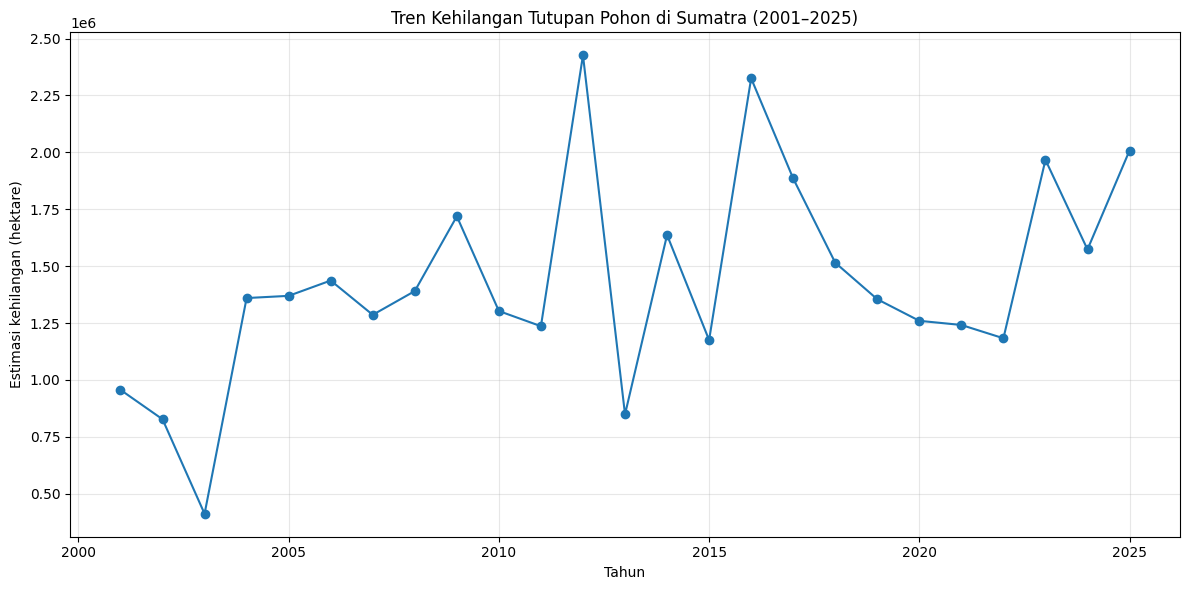

Grafik berhasil disimpan.


In [33]:
plt.figure(figsize=(12, 6))

plt.plot(
    data["tahun"],
    data["kehilangan_ha"],
    marker="o"
)

plt.title(
    "Tren Kehilangan Tutupan Pohon di Sumatra (2001–2025)"
)
plt.xlabel("Tahun")
plt.ylabel("Estimasi kehilangan (hektare)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafik_kehilangan_tutupan_pohon_sumatra.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan.")

In [34]:
from google.colab import files

files.download(
    "grafik_kehilangan_tutupan_pohon_sumatra.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>